# 02 — Baseline Modeling Template

Plantilla reutilizable para construir y comparar modelos iniciales de **clasificación** y **regresión**. Está pensada para ejecutarse después del EDA y cambiarse principalmente desde la sección de configuración.

## Estructura de trabajo

1. **Configuración y carga:** definir dataset, target y opciones del experimento.
2. **Preparación:** detectar el tipo de problema, separar features y target, y crear train/test.
3. **Preprocessing:** imputación, escalado opcional y One-Hot Encoding dentro de pipelines para evitar data leakage.
4. **Baseline y comparación:** Dummy, modelo lineal, Random Forest y XGBoost (si está instalado), evaluados mediante cross-validation sobre train.
5. **Evaluación final:** seleccionar el modelo según cross-validation y evaluarlo una sola vez sobre test.
6. **Interpretabilidad:** feature importance nativa, permutation importance y SHAP (opcional).
7. **Exportación:** guardar el pipeline completo si se desea.

> **Importante:** el conjunto de test no se utiliza para elegir hiperparámetros ni seleccionar el modelo. La selección se realiza con cross-validation sobre train; test queda reservado para la evaluación final.

### Métrica LogRMSE

Para targets no negativos se incluye **LogRMSE (RMSLE)**:

\[
\text{LogRMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left[\log(1+y_i)-\log(1+\hat{y}_i)\right]^2}
\]

Es el RMSE calculado sobre `log1p(y)`, por lo que penaliza los errores relativos de otra manera que el RMSE tradicional. Si las predicciones son negativas, se recortan a cero **solo para calcular esta métrica**. Si el target contiene valores negativos, LogRMSE no está definida y se informa como `NaN`.

## 1. Configuración

In [15]:
from pathlib import Path

# Dataset y variable objetivo
DATA_PATH = Path("Dataset/Telco/Telco-Customer-Churn.csv")
TARGET = "Churn"                 # Cambiar por el nombre de la variable objetivo
SEPARATOR = ","
READ_CSV_KWARGS = {}              # Ejemplo: {"encoding": "utf-8"}


# Statistical feature analysis
STAT_TEST_ALPHA = 0.05
STAT_TEST_MAX_CATEGORIES = 30

# Tipo de problema: "auto", "classification" o "regression".
# En caso de duda, especificarlo manualmente.
PROBLEM_TYPE = "auto"

# Columnas que no deben utilizarse como predictoras
DROP_COLUMNS = ['customerID']                 # Ejemplo: ["customer_id"]
ID_COLUMNS = []                   # Se excluyen junto con DROP_COLUMNS

# Overrides opcionales para columnas cuyo dtype no refleja su significado
DATETIME_COLUMNS = []             # Fechas guardadas como texto; se convertirán a datetime
FORCE_NUMERIC_COLUMNS = []        # Números guardados como texto
FORCE_CATEGORICAL_COLUMNS = []    # Códigos numéricos que representan categorías

# Split y validación
TEST_SIZE = 0.20
RANDOM_STATE = 42
CV_FOLDS = 5
CV_N_JOBS = -1

# Preprocessing / modelos
SCALE_NUMERIC_FOR_LINEAR_MODELS = True
OHE_MAX_CATEGORIES = 100         # Agrupa categorías poco frecuentes; usar None para no limitar
N_ESTIMATORS = 300

# Interpretabilidad y rendimiento
RUN_PERMUTATION_IMPORTANCE = True
PERMUTATION_REPEATS = 5
RUN_SHAP = True                  # Si SHAP no está instalado, la sección se omite
SHAP_MAX_SAMPLE = 150            # Máximo de filas explicadas
SHAP_BACKGROUND_SIZE = 50        # Muestra de referencia para SHAP

# Exportación opcional
SAVE_MODEL = False
MODEL_OUTPUT_PATH = Path("baseline_model.joblib")

print("Configuración cargada.")

Configuración cargada.


## 2. Imports y configuración visual

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, mean_absolute_error,
    mean_squared_error, precision_recall_curve, precision_score,
    r2_score, recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_score, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.utils.multiclass import type_of_target

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

try:
    from xgboost import XGBClassifier, XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost no está instalado. Se omitirán sus modelos.")

print(f"Pandas: {pd.__version__} | NumPy: {np.__version__}")
print(f"XGBoost disponible: {XGBOOST_AVAILABLE}")

Pandas: 2.2.3 | NumPy: 2.2.4
XGBoost disponible: True


## 3. Carga y validaciones iniciales

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {DATA_PATH.resolve()}\n"
        "Actualizá DATA_PATH en la sección de configuración."
    )

# Para otros formatos, reemplazar esta línea por el lector correspondiente.
df = pd.read_csv(DATA_PATH, sep=SEPARATOR, **READ_CSV_KWARGS)

print(f"Dataset: {DATA_PATH}")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")
display(df.head())

if TARGET is None:
    raise ValueError("Definí TARGET en la sección de configuración para entrenar modelos.")
if TARGET not in df.columns:
    raise KeyError(f"La columna TARGET='{TARGET}' no existe en el dataset.")
if df.empty:
    raise ValueError("El dataset está vacío.")

Dataset: Dataset/Telco/Telco-Customer-Churn.csv
Dimensiones: 7,043 filas × 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Preparación de features y target

En esta sección se hacen únicamente conversiones deterministas necesarias para preparar los datos. **No se imputan ni se escalan features fuera del Pipeline**: esas transformaciones se aprenden dentro de cada fold de cross-validation y luego sobre todo el conjunto de entrenamiento.

Las columnas de fecha se convierten en componentes numéricos (año, mes, día, día de la semana, etc.). Las fechas guardadas como texto deben declararse en `DATETIME_COLUMNS`.

In [4]:
from pandas.api.types import (
    is_bool_dtype, is_datetime64_any_dtype, is_numeric_dtype
)

# Trabajamos sobre una copia: df permanece intacto.
model_df = df.copy()
rows_before = len(model_df)
model_df = model_df.dropna(subset=[TARGET]).copy()
print(f"Filas sin target descartadas: {rows_before - len(model_df):,}")

# Conversión explícita de columnas configuradas como fecha.
for col in DATETIME_COLUMNS:
    if col in model_df.columns and col != TARGET:
        model_df[col] = pd.to_datetime(model_df[col], errors="coerce")

# Conversión opcional de columnas numéricas almacenadas como texto.
for col in FORCE_NUMERIC_COLUMNS:
    if col in model_df.columns and col != TARGET:
        model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

# Conversión opcional de códigos numéricos a categorías.
for col in FORCE_CATEGORICAL_COLUMNS:
    if col in model_df.columns and col != TARGET:
        model_df[col] = model_df[col].astype("string")

# Inferencia del tipo de problema.
def infer_problem_type(y, configured_type="auto"):
    configured_type = configured_type.lower()
    if configured_type in {"classification", "regression"}:
        return configured_type
    if configured_type != "auto":
        raise ValueError("PROBLEM_TYPE debe ser 'auto', 'classification' o 'regression'.")

    unique_count = y.nunique(dropna=True)
    unique_ratio = unique_count / max(len(y), 1)
    numeric_target = is_numeric_dtype(y) and not is_bool_dtype(y)

    if (not numeric_target) or (unique_count <= 20 and unique_ratio <= 0.05):
        return "classification"
    return "regression"

problem_type = infer_problem_type(model_df[TARGET], PROBLEM_TYPE)
print(f"Tipo de problema detectado: {problem_type.upper()}")

# Preparar target y eliminar registros que no puedan convertirse en el tipo esperado.
label_encoder = None
if problem_type == "classification":
    valid_target = model_df[TARGET].notna()
    model_df = model_df.loc[valid_target].copy()
    label_encoder = LabelEncoder()
    y = pd.Series(
        label_encoder.fit_transform(model_df[TARGET].astype(str)),
        index=model_df.index,
        name=TARGET
    )
    class_names = [str(value) for value in label_encoder.classes_]
    print(f"Cantidad de clases: {len(class_names)}")
    print("Clases:", class_names)
else:
    y_numeric = pd.to_numeric(model_df[TARGET], errors="coerce")
    valid_target = y_numeric.notna()
    dropped = int((~valid_target).sum())
    if dropped:
        print(f"Filas con target no numérico descartadas: {dropped:,}")
    model_df = model_df.loc[valid_target].copy()
    y = y_numeric.loc[valid_target].astype(float).rename(TARGET)

# Excluir el target y las columnas configuradas como no predictoras.
excluded_columns = set([TARGET] + DROP_COLUMNS + ID_COLUMNS)
missing_exclusions = [c for c in DROP_COLUMNS + ID_COLUMNS if c not in model_df.columns]
if missing_exclusions:
    print("Aviso: columnas configuradas para excluir que no existen:", missing_exclusions)

feature_columns = [c for c in model_df.columns if c not in excluded_columns]
if not feature_columns:
    raise ValueError("No quedaron features. Revisá TARGET, DROP_COLUMNS e ID_COLUMNS.")

X = model_df[feature_columns].copy()

# Extraer componentes útiles de fechas y eliminar las columnas datetime originales.
def expand_datetime_features(dataframe):
    result = dataframe.copy()
    datetime_cols = [
        col for col in result.columns
        if is_datetime64_any_dtype(result[col])
    ]
    for col in datetime_cols:
        dt = pd.to_datetime(result[col], errors="coerce")
        result[f"{col}__year"] = dt.dt.year
        result[f"{col}__month"] = dt.dt.month
        result[f"{col}__day"] = dt.dt.day
        result[f"{col}__dayofweek"] = dt.dt.dayofweek
        result[f"{col}__dayofyear"] = dt.dt.dayofyear
        result[f"{col}__hour"] = dt.dt.hour
        result[f"{col}__is_month_start"] = dt.dt.is_month_start.astype("float")
        result[f"{col}__is_month_end"] = dt.dt.is_month_end.astype("float")
        result = result.drop(columns=col)
    return result

X = expand_datetime_features(X)

# Convertir las columnas no numéricas a string para que OneHotEncoder maneje
# de forma consistente categorías de distintos tipos.
numeric_columns = [
    col for col in X.columns
    if is_numeric_dtype(X[col]) and not is_bool_dtype(X[col])
]
categorical_columns = [col for col in X.columns if col not in numeric_columns]
for col in categorical_columns:
    # Usar object + np.nan evita incompatibilidades de SimpleImputer con pd.NA
    # en algunas combinaciones de pandas / scikit-learn.
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

print(f"Features disponibles: {X.shape[1]}")
print(f"Numéricas: {len(numeric_columns)} | Categóricas: {len(categorical_columns)}")
print(f"Observaciones para modelado: {len(X):,}")
display(pd.DataFrame({
    "column": X.columns,
    "dtype": [str(X[col].dtype) for col in X.columns],
    "n_unique": [X[col].nunique(dropna=True) for col in X.columns],
    "missing_%": [X[col].isna().mean() * 100 for col in X.columns]
}))

Filas sin target descartadas: 0
Tipo de problema detectado: CLASSIFICATION
Cantidad de clases: 2
Clases: ['No', 'Yes']
Features disponibles: 19
Numéricas: 3 | Categóricas: 16
Observaciones para modelado: 7,043


,column,dtype,n_unique,missing_%
0,gender,object,2,0.0
1,SeniorCitizen,int64,2,0.0
2,Partner,object,2,0.0
3,Dependents,object,2,0.0
4,tenure,int64,73,0.0
5,PhoneService,object,2,0.0
6,MultipleLines,object,3,0.0
7,InternetService,object,3,0.0
8,OnlineSecurity,object,3,0.0
9,OnlineBackup,object,3,0.0


## 5. Train/test split

Se separa un conjunto de test que no participa en cross-validation ni en la selección del modelo. En clasificación se intenta mantener la proporción de clases mediante `stratify`; si alguna clase tiene menos de dos observaciones, se desactiva la estratificación y se muestra una advertencia.

In [5]:
if len(X) < 10:
    raise ValueError("Hay muy pocas observaciones para realizar un baseline confiable (mínimo recomendado: 10).")

stratify_values = None
if problem_type == "classification":
    class_counts = y.value_counts()
    if class_counts.min() >= 2:
        stratify_values = y
    else:
        print("Advertencia: alguna clase tiene menos de 2 observaciones; el split no será estratificado.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=stratify_values
)

print(f"Train: {X_train.shape[0]:,} filas")
print(f"Test:  {X_test.shape[0]:,} filas")

if problem_type == "classification":
    train_distribution = y_train.value_counts(normalize=True).sort_index()
    test_distribution = y_test.value_counts(normalize=True).sort_index()
    split_distribution = pd.DataFrame({
        "train_%": train_distribution * 100,
        "test_%": test_distribution * 100
    }).fillna(0)
    split_distribution.index = [class_names[int(i)] for i in split_distribution.index]
    display(split_distribution.round(2))

Train: 5,634 filas
Test:  1,409 filas


,train_%,test_%
No,73.46,73.46
Yes,26.54,26.54


## 5.1. Statistical Feature Analysis

En esta sección se realizan pruebas estadísticas para explorar la relación
entre las variables predictoras y la variable objetivo.

Los tests utilizados dependen del tipo de problema:

**Classification:**
- Numerical Features: One-Way ANOVA. Evalúa si existen diferencias
  significativas entre las medias de una variable numérica para las
  distintas clases del target.
- Categorical Features: Chi-Squared Test of Independence. Evalúa si
  existe una asociación estadísticamente significativa entre una
  variable categórica y el target.

**Regression:**
- Numerical Features: Pearson y Spearman Correlation. Evalúan la
  relación lineal y monotónica con el target.
- Categorical Features: One-Way ANOVA. Evalúa si existen diferencias
  significativas en la media del target entre las distintas categorías.

Los tests se realizan exclusivamente sobre el conjunto de entrenamiento,
para evitar utilizar información del test durante el análisis.

También se aplica la corrección de Benjamini-Hochberg para controlar
la tasa de falsos descubrimientos al realizar múltiples pruebas.

Importante: estos tests permiten identificar asociaciones estadísticas,
pero no implican causalidad ni determinan por sí solos la importancia
predictiva de una variable.

In [16]:

from scipy import stats
from scipy.stats import chi2_contingency


# --------------------------------------------------
# Helper functions
# --------------------------------------------------

def benjamini_hochberg(p_values):
    """Adjust p-values using the Benjamini-Hochberg procedure."""

    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)

    valid = np.isfinite(p_values)
    p = p_values[valid]
    m = len(p)

    if m == 0:
        return adjusted

    order = np.argsort(p)
    ranked = p[order]

    adjusted_sorted = ranked * m / np.arange(1, m + 1)
    adjusted_sorted = np.minimum.accumulate(
        adjusted_sorted[::-1]
    )[::-1]

    adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

    unsorted = np.empty(m)
    unsorted[order] = adjusted_sorted

    adjusted[valid] = unsorted

    return adjusted


def one_way_anova(values, groups):
    """
    Run one-way ANOVA and calculate eta-squared.

    Returns None when the data is insufficient.
    """

    tmp = pd.DataFrame({
        "value": pd.to_numeric(values, errors="coerce"),
        "group": groups
    }, index=values.index)

    tmp = tmp.replace([np.inf, -np.inf], np.nan).dropna()

    grouped = [
        group.to_numpy(dtype=float)
        for _, group in tmp.groupby("group", observed=False)["value"]
    ]

    if len(grouped) < 2 or any(len(group) < 2 for group in grouped):
        return None

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        result = stats.f_oneway(*grouped)

    if not np.isfinite(result.statistic) or not np.isfinite(result.pvalue):
        return None

    all_values = np.concatenate(grouped)
    grand_mean = all_values.mean()

    ss_total = np.sum((all_values - grand_mean) ** 2)

    ss_between = sum(
        len(group) * (group.mean() - grand_mean) ** 2
        for group in grouped
    )

    eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

    return {
        "F_statistic": float(result.statistic),
        "p_value": float(result.pvalue),
        "Eta_squared": float(eta_squared),
        "N": len(all_values),
        "Groups": len(grouped)
    }


def collapse_rare_categories(series, max_categories=30):
    """Group rare categories into an OTHER category."""

    series = series.astype("string")
    counts = series.value_counts(dropna=True)

    keep = counts[counts >= 2].head(max_categories - 1).index

    return series.where(
        series.isna() | series.isin(keep),
        "__OTHER__"
    )


# --------------------------------------------------
# Statistical tests
# --------------------------------------------------

if STAT_TEST_MAX_CATEGORIES < 2:
    raise ValueError("STAT_TEST_MAX_CATEGORIES debe ser al menos 2.")

y_train_stats = y_train.reindex(X_train.index)

if problem_type == "classification":

    # ==============================================
    # ANOVA: Numerical Features vs Classification Target
    # ==============================================

    anova_records = []

    for col in numeric_columns:

        result = one_way_anova(
            X_train[col],
            y_train_stats
        )

        if result is not None:
            anova_records.append({
                "Feature": col,
                **result
            })

    anova_results = pd.DataFrame(anova_records)

    if not anova_results.empty:

        anova_results["p_value_BH"] = benjamini_hochberg(
            anova_results["p_value"]
        )

        anova_results["Significant_BH"] = (
            anova_results["p_value_BH"] < STAT_TEST_ALPHA
        )

        anova_results = anova_results.sort_values(
            "p_value_BH"
        ).reset_index(drop=True)

        print("ANOVA — Numerical Features")
        display(anova_results.round(5))

    else:
        print("No numerical features available for ANOVA.")


    # ==============================================
    # CHI-SQUARED: Categorical Features vs Target
    # ==============================================

    chi2_records = []

    for col in categorical_columns:

        valid = X_train[col].notna() & y_train_stats.notna()

        feature = collapse_rare_categories(
            X_train.loc[valid, col],
            max_categories=STAT_TEST_MAX_CATEGORIES
        )

        target = y_train_stats.loc[valid]

        contingency_table = pd.crosstab(feature, target)

        if contingency_table.shape[0] < 2 or contingency_table.shape[1] < 2:
            continue

        chi2_stat, p_value, dof, expected = chi2_contingency(
            contingency_table,
            correction=False
        )

        n = contingency_table.to_numpy().sum()
        rows, cols = contingency_table.shape

        cramers_v = np.sqrt(
            chi2_stat / (n * min(rows - 1, cols - 1))
        ) if n > 0 else np.nan

        expected_lt5_pct = (expected < 5).mean() * 100

        chi2_records.append({
            "Feature": col,
            "Chi2": chi2_stat,
            "p_value": p_value,
            "Degrees_of_Freedom": dof,
            "Cramers_V": cramers_v,
            "Categories": rows,
            "N": n,
            "Expected_<5_%": expected_lt5_pct
        })

    chi2_results = pd.DataFrame(chi2_records)

    if not chi2_results.empty:

        chi2_results["p_value_BH"] = benjamini_hochberg(
            chi2_results["p_value"]
        )

        chi2_results["Significant_BH"] = (
            chi2_results["p_value_BH"] < STAT_TEST_ALPHA
        )

        chi2_results = chi2_results.sort_values(
            "p_value_BH"
        ).reset_index(drop=True)

        print("\nChi-Squared — Categorical Features")
        display(chi2_results.round(5))

        if (chi2_results["Expected_<5_%"] > 20).any():
            print(
                "Warning: Algunas tablas tienen más del 20% de sus "
                "frecuencias esperadas por debajo de 5. "
                "Interpretar sus p-values con precaución."
            )

    else:
        print("No categorical features available for Chi-Squared.")


# ==============================================
# REGRESSION
# ==============================================

else:

    # ==============================================
    # CORRELATION: Numerical Features vs Target
    # ==============================================

    correlation_records = []

    for col in numeric_columns:

        tmp = pd.DataFrame({
            "feature": pd.to_numeric(X_train[col], errors="coerce"),
            "target": pd.to_numeric(y_train_stats, errors="coerce")
        }).replace([np.inf, -np.inf], np.nan).dropna()

        if (
            len(tmp) < 3
            or tmp["feature"].nunique() < 2
            or tmp["target"].nunique() < 2
        ):
            continue

        pearson = stats.pearsonr(
            tmp["feature"],
            tmp["target"]
        )

        spearman = stats.spearmanr(
            tmp["feature"],
            tmp["target"]
        )

        correlation_records.append({
            "Feature": col,
            "Pearson_r": pearson.statistic,
            "Pearson_p": pearson.pvalue,
            "Spearman_rho": spearman.statistic,
            "Spearman_p": spearman.pvalue,
            "N": len(tmp)
        })

    correlation_results = pd.DataFrame(correlation_records)

    if not correlation_results.empty:

        correlation_results["Pearson_p_BH"] = benjamini_hochberg(
            correlation_results["Pearson_p"]
        )

        correlation_results["Spearman_p_BH"] = benjamini_hochberg(
            correlation_results["Spearman_p"]
        )

        correlation_results["Pearson_Significant"] = (
            correlation_results["Pearson_p_BH"] < STAT_TEST_ALPHA
        )

        correlation_results["Spearman_Significant"] = (
            correlation_results["Spearman_p_BH"] < STAT_TEST_ALPHA
        )

        correlation_results = correlation_results.sort_values(
            "Spearman_p_BH"
        ).reset_index(drop=True)

        print("Correlation Tests — Numerical Features")
        display(correlation_results.round(5))

    else:
        print("No numerical features available for correlation tests.")


    # ==============================================
    # ANOVA: Categorical Features vs Regression Target
    # ==============================================

    categorical_anova_records = []

    for col in categorical_columns:

        valid = X_train[col].notna() & y_train_stats.notna()

        feature = collapse_rare_categories(
            X_train.loc[valid, col],
            max_categories=STAT_TEST_MAX_CATEGORIES
        )

        target = y_train_stats.loc[valid]

        result = one_way_anova(
            target,
            feature
        )

        if result is not None:
            categorical_anova_records.append({
                "Feature": col,
                **result
            })

    categorical_anova_results = pd.DataFrame(
        categorical_anova_records
    )

    if not categorical_anova_results.empty:

        categorical_anova_results["p_value_BH"] = benjamini_hochberg(
            categorical_anova_results["p_value"]
        )

        categorical_anova_results["Significant_BH"] = (
            categorical_anova_results["p_value_BH"] < STAT_TEST_ALPHA
        )

        categorical_anova_results = categorical_anova_results.sort_values(
            "p_value_BH"
        ).reset_index(drop=True)

        print("\nANOVA — Categorical Features vs Regression Target")
        display(categorical_anova_results.round(5))

    else:
        print("No categorical features available for ANOVA.")

print("\nStatistical analysis completed.")


ANOVA — Numerical Features


,Feature,F_statistic,p_value,Eta_squared,N,Groups,p_value_BH,Significant_BH
0,tenure,763.89018,0.0,0.11943,5634,2,0.0,True
1,MonthlyCharges,229.90382,0.0,0.03922,5634,2,0.0,True
2,SeniorCitizen,121.97961,0.0,0.02120,5634,2,0.0,True



Chi-Squared — Categorical Features


,Feature,Chi2,p_value,Degrees_of_Freedom,Cramers_V,Categories,N,Expected_<5_%,p_value_BH,Significant_BH
0,Contract,952.30803,0.00000,2,0.41113,3,5634,0.0,0.00000,True
1,OnlineSecurity,694.28055,0.00000,2,0.35104,3,5634,0.0,0.00000,True
2,TechSupport,670.30579,0.00000,2,0.34493,3,5634,0.0,0.00000,True
3,InternetService,600.84664,0.00000,2,0.32657,3,5634,0.0,0.00000,True
4,PaymentMethod,545.21444,0.00000,3,0.31108,4,5634,0.0,0.00000,True
5,OnlineBackup,488.03778,0.00000,2,0.29432,3,5634,0.0,0.00000,True
6,DeviceProtection,441.28409,0.00000,2,0.27987,3,5634,0.0,0.00000,True
7,StreamingMovies,302.43004,0.00000,2,0.23169,3,5634,0.0,0.00000,True
8,StreamingTV,299.01657,0.00000,2,0.23038,3,5634,0.0,0.00000,True
9,PaperlessBilling,220.83364,0.00000,1,0.19798,2,5634,0.0,0.00000,True



Statistical analysis completed.


In [19]:

def plot_statistical_scores(
    results,
    score_column,
    title,
    top_n=25,
    cmap="YlGnBu"
):
    """
    Plot a heatmap of statistical feature scores.

    Parameters
    ----------
    results : pd.DataFrame
        Results from a statistical test.
    score_column : str
        Column containing the statistical score.
    title : str
        Plot title.
    top_n : int
        Maximum number of features to display.
    cmap : str
        Seaborn color palette.
    """

    if results is None or results.empty:
        print(f"No results available for: {title}")
        return

    plot_df = results[["Feature", score_column]].copy()

    plot_df[score_column] = pd.to_numeric(
        plot_df[score_column],
        errors="coerce"
    )

    plot_df = plot_df.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    if plot_df.empty:
        print(f"No valid scores available for: {title}")
        return

    # Rank features by statistical score
    plot_df = (
        plot_df.sort_values(score_column, ascending=False)
        .head(top_n)
        .copy()
    )

    # Mark statistically significant features
    if "Significant_BH" in results.columns:
        significance = results.set_index("Feature")[
            "Significant_BH"
        ]

        plot_df["Feature"] = plot_df["Feature"].apply(
            lambda feature: (
                f"{feature} *"
                if significance.get(feature, False)
                else feature
            )
        )

    plot_df = plot_df.set_index("Feature")

    # Dynamic figure size
    fig_height = max(3, min(0.42 * len(plot_df) + 1, 15))

    plt.figure(figsize=(7, fig_height))

    sns.heatmap(
        plot_df,
        annot=True,
        cmap=cmap,
        linewidths=0.4,
        linecolor="black",
        fmt=".2f",
        cbar_kws={"label": score_column}
    )

    plt.title(title, fontsize=13, pad=15)
    plt.xlabel("")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()


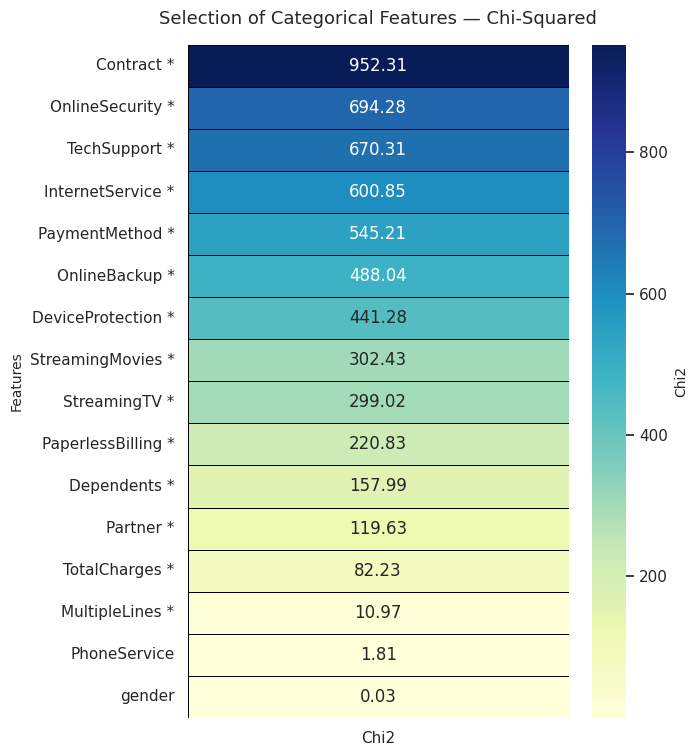

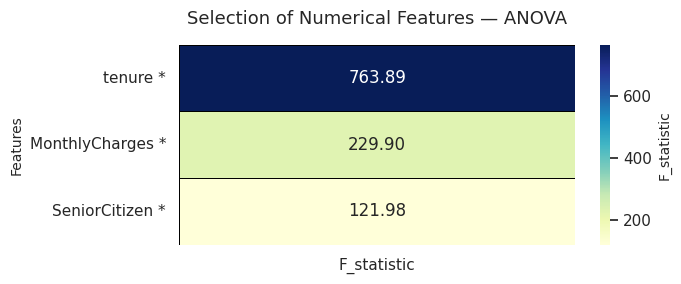

In [20]:

if problem_type == "classification":

    # Categorical Features — Chi-Squared
    plot_statistical_scores(
        results=chi2_results,
        score_column="Chi2",
        title="Selection of Categorical Features — Chi-Squared",
        top_n=25
    )

    # Numerical Features — ANOVA
    plot_statistical_scores(
        results=anova_results,
        score_column="F_statistic",
        title="Selection of Numerical Features — ANOVA",
        top_n=25
    )

else:
    print(
        "These visualizations are configured for classification. "
        "For regression, use the corresponding correlation and "
        "categorical ANOVA results."
    )


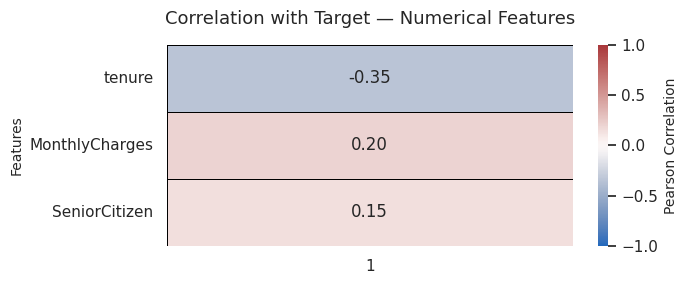

In [22]:

def plot_target_correlation(
    correlations,
    top_n=25,
    cmap="vlag"
):
    """Plot numerical feature correlations with the target."""

    if correlations is None or correlations.empty:
        print("No correlations available to plot.")
        return

    # Rank features by maximum absolute correlation
    correlations = correlations.copy()

    correlations["_ranking"] = (
        correlations.abs().max(axis=1)
    )

    correlations = (
        correlations
        .sort_values("_ranking", ascending=False)
        .drop(columns="_ranking")
        .head(top_n)
    )

    fig_height = max(
        3,
        min(0.42 * len(correlations) + 1, 15)
    )

    plt.figure(figsize=(7, fig_height))

    sns.heatmap(
        correlations,
        annot=True,
        cmap=cmap,
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.4,
        linecolor="black",
        fmt=".2f",
        cbar_kws={"label": "Pearson Correlation"}
    )

    plt.title(
        "Correlation with Target — Numerical Features",
        fontsize=13,
        pad=15
    )

    plt.xlabel("")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()


plot_target_correlation(
    target_correlations,
    top_n=25
)


## 6. Preprocessing y modelos

Los imputadores, el escalado y el One-Hot Encoding viven dentro de un `ColumnTransformer` integrado a cada Pipeline. De este modo, en cada fold de cross-validation los parámetros del preprocessing se calculan únicamente con la parte de entrenamiento de ese fold.

Se prueban modelos sencillos junto con Random Forest y XGBoost. XGBoost se incorpora solo si está instalado (`pip install xgboost`).

In [6]:
def make_one_hot_encoder():
    """Crea un OneHotEncoder compatible con distintas versiones de scikit-learn."""
    kwargs = {"handle_unknown": "ignore"}
    if OHE_MAX_CATEGORIES is not None:
        kwargs["max_categories"] = OHE_MAX_CATEGORIES
        kwargs["handle_unknown"] = "infrequent_if_exist"
    try:
        return OneHotEncoder(sparse_output=True, **kwargs)
    except TypeError:
        # Compatibilidad con versiones anteriores a sparse_output.
        kwargs.pop("max_categories", None)
        kwargs["handle_unknown"] = "ignore"
        return OneHotEncoder(sparse=True, **kwargs)


def make_numeric_imputer():
    try:
        return SimpleImputer(strategy="median", keep_empty_features=True)
    except TypeError:
        # Compatibilidad con versiones antiguas de scikit-learn.
        return SimpleImputer(strategy="median")


def build_preprocessor(scale_numeric=False):
    transformers = []

    if numeric_columns:
        numeric_steps = [("imputer", make_numeric_imputer())]
        if scale_numeric:
            numeric_steps.append(("scaler", StandardScaler()))
        numeric_pipeline = Pipeline(steps=numeric_steps)
        transformers.append(("num", numeric_pipeline, numeric_columns))

    if categorical_columns:
        categorical_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("onehot", make_one_hot_encoder())
        ])
        transformers.append(("cat", categorical_pipeline, categorical_columns))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=True
    )


def build_model_pipelines():
    models = {}
    if problem_type == "classification":
        models["Dummy"] = (DummyClassifier(strategy="most_frequent"), False)
        models["Logistic Regression"] = (
            LogisticRegression(max_iter=2000, class_weight=None), True
        )
        models["Random Forest"] = (
            RandomForestClassifier(
                n_estimators=N_ESTIMATORS,
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
                n_jobs=1,
                class_weight="balanced"
            ), False
        )
        if XGBOOST_AVAILABLE:
            objective = "binary:logistic" if y.nunique() == 2 else "multi:softprob"
            xgb_kwargs = dict(
                n_estimators=N_ESTIMATORS,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=1.0,
                random_state=RANDOM_STATE,
                n_jobs=1,
                eval_metric="logloss" if y.nunique() == 2 else "mlogloss"
            )
            if y.nunique() > 2:
                xgb_kwargs["num_class"] = int(y.nunique())
            models["XGBoost"] = (XGBClassifier(objective=objective, **xgb_kwargs), False)
    else:
        models["Dummy"] = (DummyRegressor(strategy="mean"), False)
        models["Ridge Regression"] = (Ridge(alpha=1.0), True)
        models["Random Forest"] = (
            RandomForestRegressor(
                n_estimators=N_ESTIMATORS,
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
                n_jobs=1
            ), False
        )
        if XGBOOST_AVAILABLE:
            models["XGBoost"] = (
                XGBRegressor(
                    n_estimators=N_ESTIMATORS,
                    max_depth=5,
                    learning_rate=0.05,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    reg_lambda=1.0,
                    objective="reg:squarederror",
                    random_state=RANDOM_STATE,
                    n_jobs=1
                ), False
            )

    pipelines = {}
    for name, (estimator, use_scaling) in models.items():
        pipelines[name] = Pipeline(steps=[
            ("preprocessor", build_preprocessor(
                scale_numeric=(use_scaling and SCALE_NUMERIC_FOR_LINEAR_MODELS)
            )),
            ("model", estimator)
        ])
    return pipelines


model_pipelines = build_model_pipelines()
print("Modelos incluidos:", list(model_pipelines))

Modelos incluidos: ['Dummy', 'Logistic Regression', 'Random Forest', 'XGBoost']


## 7. Comparación mediante cross-validation

Los modelos se comparan únicamente dentro del conjunto de entrenamiento. Para clasificación se utiliza **F1-weighted** como métrica de selección; para regresión, **RMSE** (minimizado). Si la clase minoritaria no tiene suficientes ejemplos para todos los folds, se reduce la cantidad de folds cuando sea posible.

In [7]:
if problem_type == "classification":
    min_class_count = int(y_train.value_counts().min())
    effective_folds = min(CV_FOLDS, min_class_count)
    if effective_folds < 2:
        raise ValueError(
            "No es posible hacer Stratified CV porque una clase tiene menos de 2 ejemplos en train. "
            "Conseguí más datos o reducí la complejidad del experimento."
        )
    cv = StratifiedKFold(n_splits=effective_folds, shuffle=True, random_state=RANDOM_STATE)
    scoring = "f1_weighted"
    selection_metric = "F1-weighted"
else:
    effective_folds = min(CV_FOLDS, len(X_train))
    if effective_folds < 2:
        raise ValueError("No hay suficientes observaciones de train para cross-validation.")
    cv = KFold(n_splits=effective_folds, shuffle=True, random_state=RANDOM_STATE)
    scoring = "neg_root_mean_squared_error"
    selection_metric = "RMSE"

print(f"Cross-validation: {effective_folds} folds | Métrica de selección: {selection_metric}")

cv_records = []
failed_models = {}

for model_name, pipeline in model_pipelines.items():
    print(f"Evaluando: {model_name}...")
    try:
        scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=CV_N_JOBS,
            error_score="raise"
        )
        cv_records.append({
            "Model": model_name,
            "CV_Mean": float(np.mean(scores)),
            "CV_Std": float(np.std(scores, ddof=1)) if len(scores) > 1 else 0.0,
            "Folds": len(scores)
        })
    except Exception as exc:
        failed_models[model_name] = str(exc)
        print(f"  No se pudo evaluar {model_name}: {type(exc).__name__}: {exc}")

if not cv_records:
    raise RuntimeError("Ningún modelo pudo completar cross-validation. Revisá los tipos de columnas y los datos.")

cv_results = pd.DataFrame(cv_records)
if problem_type == "regression":
    # cross_val_score devuelve RMSE negativo para respetar la convención de sklearn.
    cv_results["CV_RMSE"] = -cv_results["CV_Mean"]
    cv_results["CV_RMSE_Std"] = cv_results["CV_Std"]
    cv_results = cv_results.sort_values("CV_RMSE", ascending=True).reset_index(drop=True)
    cv_display = cv_results[["Model", "CV_RMSE", "CV_RMSE_Std", "Folds"]]
else:
    cv_results = cv_results.sort_values("CV_Mean", ascending=False).reset_index(drop=True)
    cv_display = cv_results.rename(columns={
        "CV_Mean": "CV_F1_weighted",
        "CV_Std": "CV_F1_weighted_Std"
    })[["Model", "CV_F1_weighted", "CV_F1_weighted_Std", "Folds"]]

print("Resultados de cross-validation (solo train):")
display(cv_display.round(4))
if failed_models:
    print("Modelos que no pudieron evaluarse:")
    for name, reason in failed_models.items():
        print(f"- {name}: {reason[:500]}")

best_model_name = cv_results.iloc[0]["Model"]
best_pipeline = clone(model_pipelines[best_model_name])
print(f"Modelo seleccionado por CV: {best_model_name}")

Cross-validation: 5 folds | Métrica de selección: F1-weighted
Evaluando: Dummy...
Evaluando: Logistic Regression...
Evaluando: Random Forest...
Evaluando: XGBoost...
Resultados de cross-validation (solo train):


,Model,CV_F1_weighted,CV_F1_weighted_Std,Folds
0,Logistic Regression,0.7936,0.0144,5
1,XGBoost,0.7886,0.0166,5
2,Random Forest,0.7819,0.0114,5
3,Dummy,0.6223,0.0001,5


Modelo seleccionado por CV: Logistic Regression


## 8. Entrenamiento final y evaluación en test

Se reentrena el pipeline seleccionado con todo `X_train` y se evalúa una sola vez sobre `X_test`. Las métricas de test son la estimación final del rendimiento del baseline.

,Metric,Test
0,Accuracy,0.7977
1,Precision_weighted,0.7884
2,Recall_weighted,0.7977
3,F1_weighted,0.7909
4,ROC_AUC,0.8387
5,PR_AUC,0.6256


Classification report:
              precision    recall  f1-score   support

          No       0.84      0.89      0.87      1035
         Yes       0.64      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



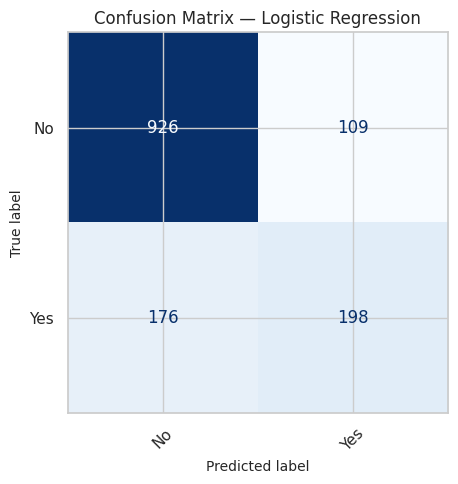

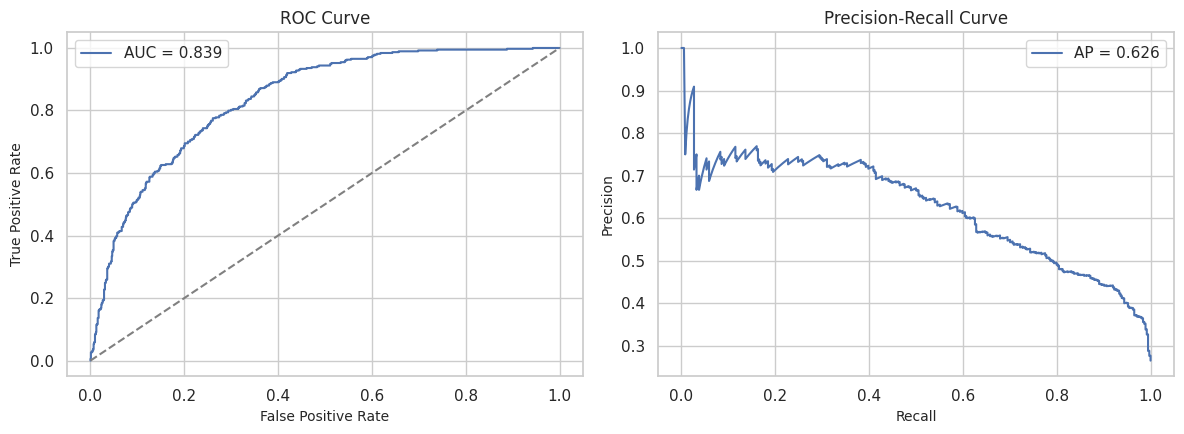

In [8]:
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

if problem_type == "classification":
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_weighted": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    }

    y_proba = None
    if hasattr(best_pipeline, "predict_proba"):
        try:
            y_proba = best_pipeline.predict_proba(X_test)
        except Exception:
            y_proba = None

    n_classes = len(label_encoder.classes_)
    if y_proba is not None:
        try:
            if n_classes == 2 and len(np.unique(y_test)) == 2:
                metrics["ROC_AUC"] = roc_auc_score(y_test, y_proba[:, 1])
                metrics["PR_AUC"] = average_precision_score(y_test, y_proba[:, 1])
            elif n_classes > 2:
                y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
                metrics["ROC_AUC"] = roc_auc_score(
                    y_test_bin, y_proba, multi_class="ovr", average="weighted"
                )
                metrics["PR_AUC_macro"] = average_precision_score(
                    y_test_bin, y_proba, average="macro"
                )
        except Exception as exc:
            print(f"No se pudieron calcular ROC-AUC/PR-AUC: {exc}")

    metrics_df = pd.DataFrame({"Metric": list(metrics), "Test": list(metrics.values())})
    display(metrics_df.round(4))

    print("Classification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(n_classes),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=np.arange(n_classes))
    fig, ax = plt.subplots(figsize=(max(6, n_classes * 0.65), max(5, n_classes * 0.55)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"Confusion Matrix — {best_model_name}")
    plt.tight_layout()
    plt.show()

    if y_proba is not None and n_classes == 2 and len(np.unique(y_test)) == 2:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        fpr, tpr, _ = roc_curve(y_test, y_proba[:, 1])
        axes[0].plot(fpr, tpr, label=f"AUC = {metrics.get('ROC_AUC', np.nan):.3f}")
        axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
        axes[0].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
        axes[0].legend()

        precision, recall, _ = precision_recall_curve(y_test, y_proba[:, 1])
        axes[1].plot(recall, precision, label=f"AP = {metrics.get('PR_AUC', np.nan):.3f}")
        axes[1].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
        axes[1].legend()
        plt.tight_layout()
        plt.show()

else:
    y_pred = np.asarray(y_pred, dtype=float)
    y_test_array = np.asarray(y_test, dtype=float)

    rmse = float(np.sqrt(mean_squared_error(y_test_array, y_pred)))
    metrics = {
        "MAE": mean_absolute_error(y_test_array, y_pred),
        "RMSE": rmse,
        "R2": r2_score(y_test_array, y_pred) if len(y_test_array) >= 2 else np.nan
    }

    # LogRMSE = RMSLE = RMSE entre log1p(y_true) y log1p(y_pred).
    # RMSLE requiere target no negativo; predicciones negativas se recortan a cero
    # únicamente para esta métrica, sin modificar y_pred ni las demás métricas.
    if np.all(y_test_array >= 0):
        negative_predictions = int(np.sum(y_pred < 0))
        y_pred_for_log = np.maximum(y_pred, 0)
        metrics["LogRMSE (RMSLE, log1p)"] = np.sqrt(mean_squared_error(
            np.log1p(y_test_array), np.log1p(y_pred_for_log)
        ))
        if negative_predictions:
            print(
                f"Nota LogRMSE: {negative_predictions} predicciones negativas se recortaron a 0 "
                "solo para calcular RMSLE."
            )
    else:
        metrics["LogRMSE (RMSLE, log1p)"] = np.nan
        print("LogRMSE no aplica: el target de test contiene valores negativos.")

    metrics_df = pd.DataFrame({"Metric": list(metrics), "Test": list(metrics.values())})
    display(metrics_df.round(4))

    predictions_df = pd.DataFrame({
        "y_true": y_test_array,
        "y_pred": y_pred,
        "residual": y_test_array - y_pred
    }, index=y_test.index)
    display(predictions_df.head(10))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    sns.scatterplot(data=predictions_df, x="y_true", y="y_pred", alpha=0.65, ax=axes[0])
    limits = [
        min(predictions_df["y_true"].min(), predictions_df["y_pred"].min()),
        max(predictions_df["y_true"].max(), predictions_df["y_pred"].max())
    ]
    axes[0].plot(limits, limits, linestyle="--", color="red")
    axes[0].set(title="Actual vs. Predicted", xlabel="Actual", ylabel="Predicted")

    sns.scatterplot(data=predictions_df, x="y_pred", y="residual", alpha=0.65, ax=axes[1])
    axes[1].axhline(0, linestyle="--", color="red")
    axes[1].set(title="Residuals vs. Predicted", xlabel="Predicted", ylabel="Residual")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(predictions_df["residual"].dropna(), bins=25, edgecolor="white", alpha=0.85)
    ax.set(title="Residual Distribution", xlabel="Residual", ylabel="Count")
    plt.tight_layout()
    plt.show()

## 9. Feature importance nativa

Para modelos basados en árboles se muestra la importancia nativa (`feature_importances_`). Para modelos lineales se utiliza el valor absoluto de los coeficientes (promediado entre clases cuando corresponde).

Las features aparecen después del preprocessing, por lo que las categorías One-Hot quedan representadas individualmente.

,Feature,Importance
68,cat__TotalCharges_24.4,1.14932
65,cat__TotalCharges_20.5,1.04804
71,cat__TotalCharges_44,0.97988
55,cat__TotalCharges_19.9,0.96961
59,cat__TotalCharges_20.15,0.96908
104,cat__TotalCharges_740.3,0.83363
56,cat__TotalCharges_19.95,0.77231
143,cat__TotalCharges_infrequent_sklearn,0.77204
66,cat__TotalCharges_20.9,0.76845
89,cat__TotalCharges_70.6,0.76625


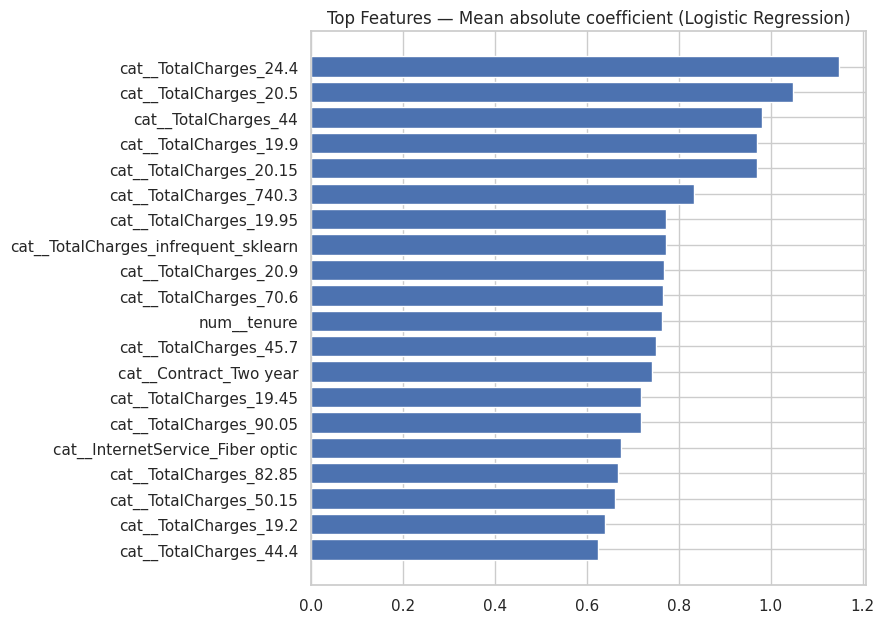

In [9]:
preprocessor_fitted = best_pipeline.named_steps["preprocessor"]
estimator_fitted = best_pipeline.named_steps["model"]

try:
    transformed_feature_names = preprocessor_fitted.get_feature_names_out()
except Exception:
    transformed_feature_names = np.array([f"feature_{i}" for i in range(
        preprocessor_fitted.transform(X_train.iloc[:1]).shape[1]
    )])

native_importance = None
importance_kind = None
if hasattr(estimator_fitted, "feature_importances_"):
    native_importance = np.asarray(estimator_fitted.feature_importances_).ravel()
    importance_kind = "Feature importance"
elif hasattr(estimator_fitted, "coef_"):
    coefficients = np.asarray(estimator_fitted.coef_)
    native_importance = np.mean(np.abs(coefficients), axis=0) if coefficients.ndim > 1 else np.abs(coefficients)
    importance_kind = "Mean absolute coefficient"

if native_importance is not None and len(native_importance) == len(transformed_feature_names):
    native_importance_df = pd.DataFrame({
        "Feature": transformed_feature_names,
        "Importance": native_importance
    }).sort_values("Importance", ascending=False)
    display(native_importance_df.head(20).round(5))

    plot_data = native_importance_df.head(20).sort_values("Importance")
    fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(plot_data))))
    ax.barh(plot_data["Feature"], plot_data["Importance"])
    ax.set_title(f"Top Features — {importance_kind} ({best_model_name})")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_model_name} no expone una importancia nativa compatible.")

## 10. Permutation Importance

Permutation importance mide cuánto cae el rendimiento al permutar cada columna. A diferencia de la importancia nativa tras One-Hot Encoding, esta versión trabaja con las columnas originales y agrupa naturalmente las categorías de una misma variable.

,Feature,Importance_Mean,Importance_Std
4,tenure,0.06351,0.00524
7,InternetService,0.05052,0.00654
14,Contract,0.03453,0.00601
17,MonthlyCharges,0.01013,0.00754
6,MultipleLines,0.00863,0.00416
10,DeviceProtection,0.00768,0.00406
8,OnlineSecurity,0.00753,0.00346
11,TechSupport,0.00633,0.00330
13,StreamingMovies,0.00486,0.00392
12,StreamingTV,0.00397,0.00625


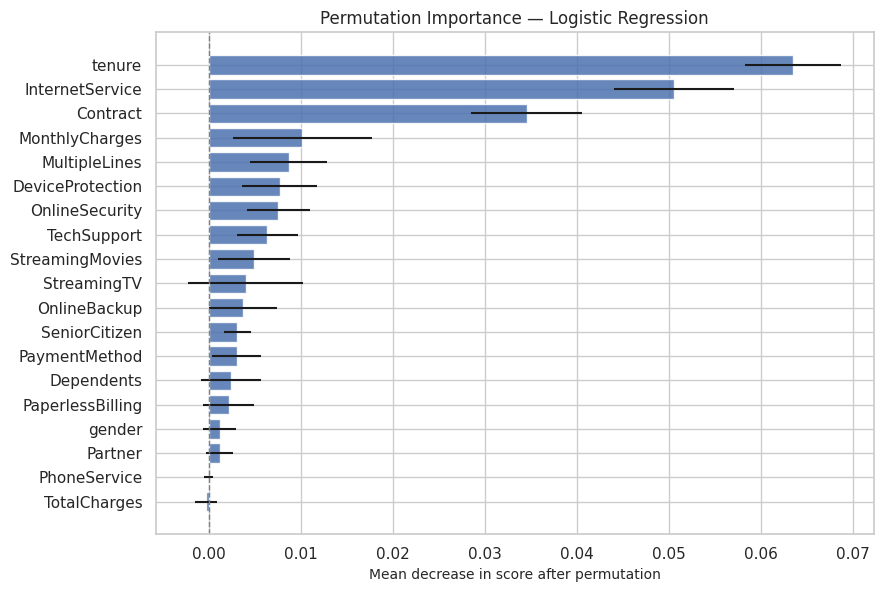

In [10]:
permutation_importance_df = None
if RUN_PERMUTATION_IMPORTANCE:
    try:
        perm = permutation_importance(
            best_pipeline,
            X_test,
            y_test,
            scoring=scoring,
            n_repeats=PERMUTATION_REPEATS,
            random_state=RANDOM_STATE,
            n_jobs=CV_N_JOBS
        )
        permutation_importance_df = pd.DataFrame({
            "Feature": X_test.columns,
            "Importance_Mean": perm.importances_mean,
            "Importance_Std": perm.importances_std
        }).sort_values("Importance_Mean", ascending=False)
        display(permutation_importance_df.head(20).round(5))

        plot_data = permutation_importance_df.head(20).sort_values("Importance_Mean")
        fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(plot_data))))
        ax.barh(
            plot_data["Feature"],
            plot_data["Importance_Mean"],
            xerr=plot_data["Importance_Std"],
            alpha=0.85
        )
        ax.axvline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_title(f"Permutation Importance — {best_model_name}")
        ax.set_xlabel("Mean decrease in score after permutation")
        plt.tight_layout()
        plt.show()
    except Exception as exc:
        print(f"No se pudo calcular permutation importance: {type(exc).__name__}: {exc}")
else:
    print("RUN_PERMUTATION_IMPORTANCE=False: sección omitida.")

## 11. SHAP Values (opcional)

SHAP ayuda a explicar cómo contribuyen las variables a las predicciones del modelo seleccionado. Se calcula sobre una muestra limitada para controlar el tiempo y la memoria. Para variables categóricas, SHAP explica las columnas transformadas por One-Hot Encoding.

Instalación opcional si no está disponible: `pip install shap`.

**Interpretación:** el summary plot muestra magnitud y dirección de las contribuciones. SHAP describe el comportamiento del modelo, no causalidad. Con variables muy correlacionadas, la atribución de importancia puede repartirse entre ellas.

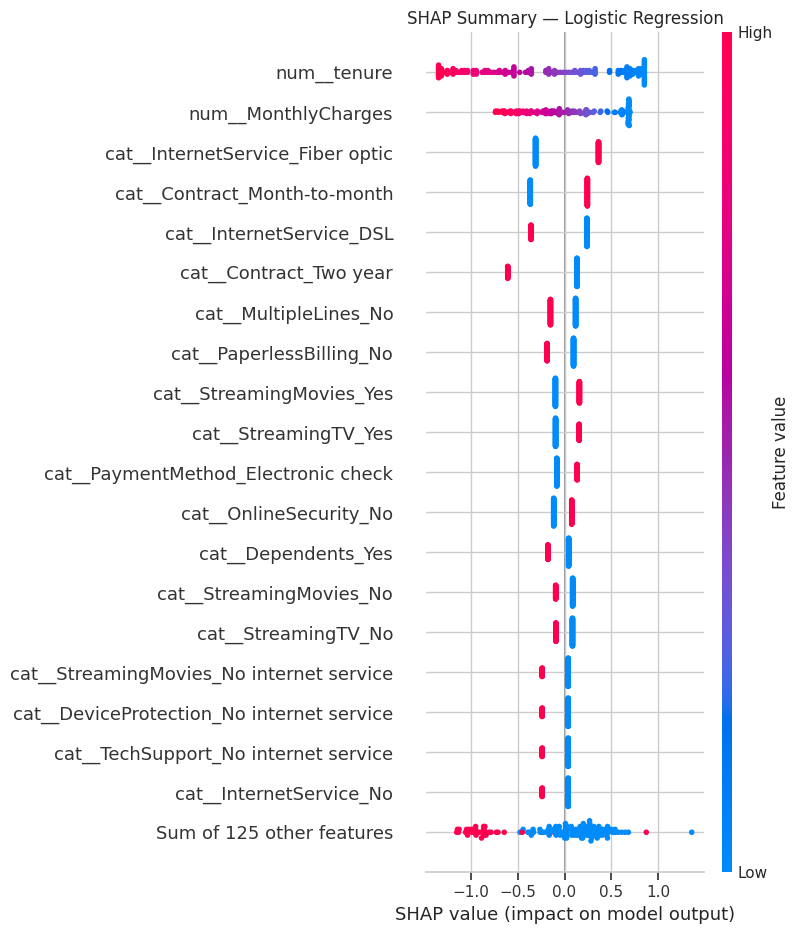

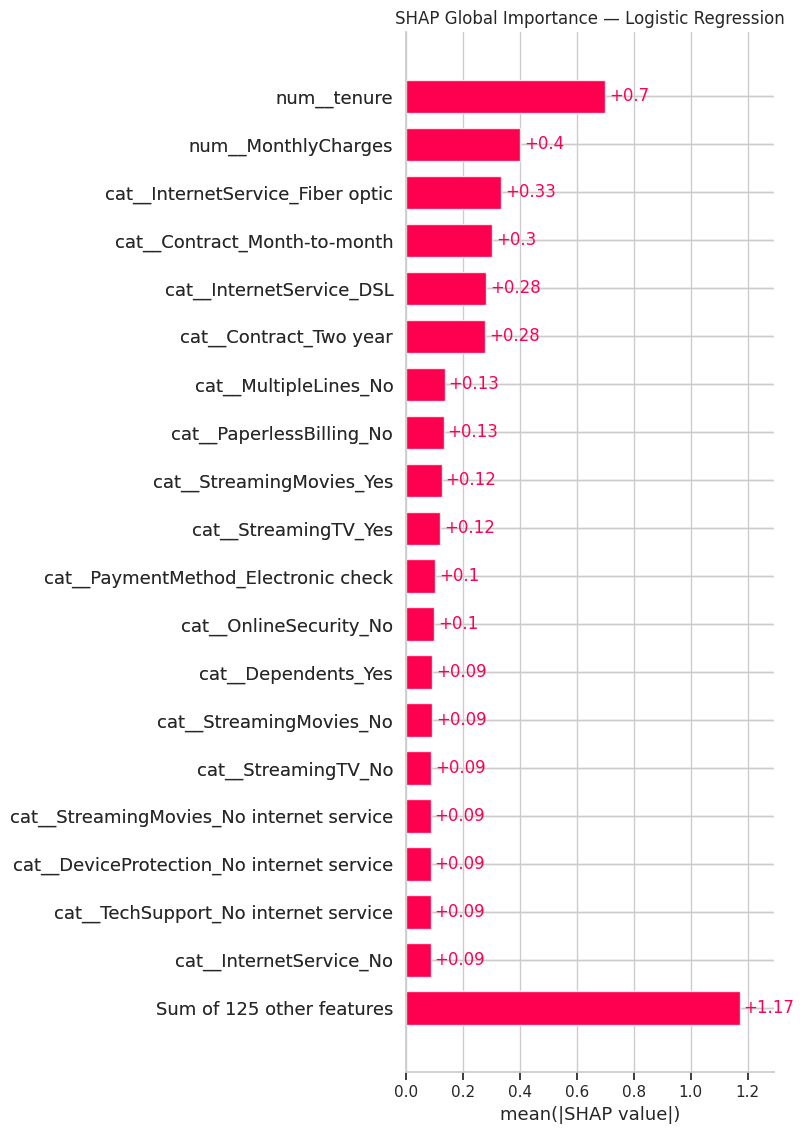

In [12]:
shap_explanation = None
if RUN_SHAP:
    try:
        import shap

        # Muestras reproducibles de train (background) y test (explicaciones).
        background_n = min(SHAP_BACKGROUND_SIZE, len(X_train))
        explain_n = min(SHAP_MAX_SAMPLE, len(X_test))
        X_background_raw = X_train.sample(n=background_n, random_state=RANDOM_STATE)
        X_explain_raw = X_test.sample(n=explain_n, random_state=RANDOM_STATE)

        X_background = preprocessor_fitted.transform(X_background_raw)
        X_explain = preprocessor_fitted.transform(X_explain_raw)
        if sparse.issparse(X_background):
            X_background = X_background.toarray()
        if sparse.issparse(X_explain):
            X_explain = X_explain.toarray()

        # SHAP necesita matrices densas en esta ruta; el tamaño queda acotado por configuración.
        X_background = np.asarray(X_background)
        X_explain = np.asarray(X_explain)
        shap_feature_names = [str(name) for name in transformed_feature_names]

        explainer = shap.Explainer(
            estimator_fitted,
            X_background,
            feature_names=shap_feature_names
        )
        raw_shap_explanation = explainer(X_explain)

        shap_values_array = np.asarray(raw_shap_explanation.values)
        base_values = np.asarray(raw_shap_explanation.base_values)

        # En clasificación multiclase/binaria, algunas versiones devuelven
        # (observaciones, features, clases). Se explica la segunda clase.
        if shap_values_array.ndim == 3:
            output_index = 1 if shap_values_array.shape[2] > 1 else 0
            shap_values_array = shap_values_array[:, :, output_index]
            if base_values.ndim == 2:
                base_values = base_values[:, output_index]

        shap_explanation = shap.Explanation(
            values=shap_values_array,
            base_values=base_values,
            data=X_explain,
            feature_names=shap_feature_names
        )

        shap.plots.beeswarm(shap_explanation, max_display=20, show=False)
        plt.title(f"SHAP Summary — {best_model_name}")
        plt.tight_layout()
        plt.show()

        shap.plots.bar(shap_explanation, max_display=20, show=False)
        plt.title(f"SHAP Global Importance — {best_model_name}")
        plt.tight_layout()
        plt.show()

    except ImportError:
        print("SHAP no está instalado. Ejecutá `%pip install shap` y volvé a correr esta sección.")
    except Exception as exc:
        print(
            f"No se pudo calcular SHAP para {best_model_name}: "
            f"{type(exc).__name__}: {exc}\n"
            "La evaluación y las importancias anteriores siguen siendo válidas."
        )
else:
    print("RUN_SHAP=False: sección omitida.")

## 12. Resumen del experimento

In [13]:
print("=" * 60)
print("BASELINE MODELING SUMMARY")
print("=" * 60)
print(f"Dataset:       {DATA_PATH}")
print(f"Target:        {TARGET}")
print(f"Problem type:  {problem_type}")
print(f"Train / Test:  {len(X_train):,} / {len(X_test):,}")
print(f"Features:      {X.shape[1]}")
print(f"Best model:    {best_model_name}")
print(f"Selection:     {selection_metric} via {effective_folds}-fold CV")
print("\nTest metrics:")
display(metrics_df.round(4))

BASELINE MODELING SUMMARY
Dataset:       Dataset/Telco/Telco-Customer-Churn.csv
Target:        Churn
Problem type:  classification
Train / Test:  5,634 / 1,409
Features:      19
Best model:    Logistic Regression
Selection:     F1-weighted via 5-fold CV

Test metrics:


,Metric,Test
0,Accuracy,0.7977
1,Precision_weighted,0.7884
2,Recall_weighted,0.7977
3,F1_weighted,0.7909
4,ROC_AUC,0.8387
5,PR_AUC,0.6256


## 13. Exportación opcional del modelo

El objeto exportado incluye el Pipeline completo (preprocessing + modelo), el tipo de problema y el `LabelEncoder` cuando se trata de clasificación. Así, las transformaciones aprendidas durante el entrenamiento se aplican de la misma forma a datos nuevos.

In [ ]:
if SAVE_MODEL:
    import joblib

    MODEL_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    artifact = {
        "pipeline": best_pipeline,
        "problem_type": problem_type,
        "target": TARGET,
        "label_encoder": label_encoder,
        "feature_columns": list(X.columns),
        "random_state": RANDOM_STATE
    }
    joblib.dump(artifact, MODEL_OUTPUT_PATH)
    print(f"Modelo guardado en: {MODEL_OUTPUT_PATH.resolve()}")
else:
    print("SAVE_MODEL=False: no se exportó ningún archivo.")

## 14. Próximos pasos

Este notebook establece una referencia inicial; no busca encontrar el mejor modelo posible. Después del baseline:

- Revisar features importantes y posibles problemas detectados en el EDA.
- Crear hipótesis de Feature Engineering y probarlas de forma controlada.
- Comparar los cambios contra este baseline manteniendo los mismos splits y métricas.
- Optimizar hiperparámetros solo después de definir una validación confiable.
- Para series temporales, reemplazar el split aleatorio y la cross-validation por una estrategia temporal (`TimeSeriesSplit` o un split por fecha).

### Notas

- Si el target numérico tiene pocas clases, `PROBLEM_TYPE="auto"` puede inferir clasificación. Confirmá el diagnóstico y configurá el tipo manualmente cuando sea necesario.
- Si hay identificadores, texto libre o columnas con información posterior al evento objetivo, evaluá excluirlas en `ID_COLUMNS` / `DROP_COLUMNS`.
- Revisá las columnas de fecha y los códigos numéricos categóricos mediante `DATETIME_COLUMNS` y `FORCE_CATEGORICAL_COLUMNS`.
- El baseline no realiza búsqueda de hiperparámetros ni elimina features automáticamente.